In [6]:
import pandas as pd
import numpy as np
from IPython.display import HTML, display
import plotly.express as px
import plotly.io as pio


# EDITAR: lista de días (ordenada) que quieres incluir en la gráfica
dates = ['20260518', '20260522', '20260603']  # añade más YYYYMMDD según tus carpetas

merged_list = []
for d in dates:
    tr_path = f'../data/experiments/{d}/trays.csv'
    tt_path = f'../data/experiments/{d}/treatment.csv'
    try:
        trays_d = pd.read_csv(tr_path)
        treatment_d = pd.read_csv(tt_path)
    except FileNotFoundError:
        continue

    trays_d['absorption'] = (trays_d['post_weight'] - trays_d['pre_weight']) / trays_d['pre_weight']
    merged_d = trays_d.merge(treatment_d, left_on='treatment_floor', right_on='treatment_id', how='inner')
    merged_d['date'] = d
    merged_list.append(merged_d)

if not merged_list:
    raise RuntimeError("No se cargaron datos para las fechas indicadas.")

merged_all = pd.concat(merged_list, ignore_index=True)

# Excluir puntos experimentales anómalos (pre_weight == post_weight)
# Ej: 20260522_A9 tiene absorción cero (fallo experimental)
merged_all = merged_all[merged_all['pre_weight'] != merged_all['post_weight']].copy()

# ordenar por treatment_value y por el orden de dates
date_cat = pd.Categorical(merged_all['date'], categories=dates, ordered=True)
merged_all = merged_all.assign(date_cat=date_cat).sort_values(['treatment_value', 'date_cat', 'tray_id'])

# calculamos un x por (treatment_value, date): todos los puntos de la misma fecha y tratamiento comparten x
n_dates = len(dates)
merged_all['date_idx'] = merged_all['date_cat'].cat.codes  # 0..n_dates-1
spacing = 0.12  # distancia entre fechas (ajusta)
merged_all['x_base'] = merged_all['treatment_value'].astype(float)
merged_all['x_pos'] = merged_all['x_base'] + (merged_all['date_idx'] - (n_dates - 1) / 2) * spacing

# etiqueta mostrada en hover / ticks: '2' para primer día, '2(2)' para segundo día, etc.
day_num = merged_all['date_idx'] + 1
merged_all['x_label'] = np.where(
    day_num == 1,
    merged_all['treatment_value'].astype(str),
    merged_all['treatment_value'].astype(str) + "(" + day_num.astype(str) + ")"
)

# construir figura: colorear por fecha para distinguir días
fig = px.scatter(
    merged_all,
    x='x_pos',
    y='absorption',
    color='date',
    hover_data=['tray_id', 'date', 'treatment_value', 'x_label', 'floor', 'position'],
    title='Treatment (por día alineado) vs Absorption',
    labels={'x_pos': 'Treatment (por fecha)', 'absorption': 'Absorption'}
)

# definir ticks en el eje x con las etiquetas combinadas (una por treatment+date)
tick_map = merged_all.drop_duplicates(subset=['x_pos', 'x_label']).sort_values('x_pos')
fig.update_layout(
    xaxis=dict(
        tickmode='array',
        tickvals=tick_map['x_pos'],
        ticktext=tick_map['x_label'],
        title='Treatment (con fechas separadas)'
    ),
    yaxis=dict(title='Absorption')
)

display(HTML(pio.to_html(fig, include_plotlyjs='cdn')))


--- Normalidad ---
Grupo 1: p=0.0767 -> Normal
Grupo 2: p=0.3085 -> Normal
Grupo 3: p=0.7462 -> Normal

--- Homocedasticidad (Levene) ---
p=0.1859 -> Homocedastico

--- ANOVA de una vía ---
F = 15.3485, p = 0.0000

--- Tukey HSD ---
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
  2 ml   5 ml   0.1564 0.0097  0.0339 0.2788   True
  2 ml   6 ml   0.2706    0.0  0.1506 0.3906   True
  5 ml   6 ml   0.1142 0.0715 -0.0082 0.2367  False
---------------------------------------------------


/var/folders/ll/hm35mj650fs_spb22x5qqnqh0000gn/T/ipykernel_1837/3738760426.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


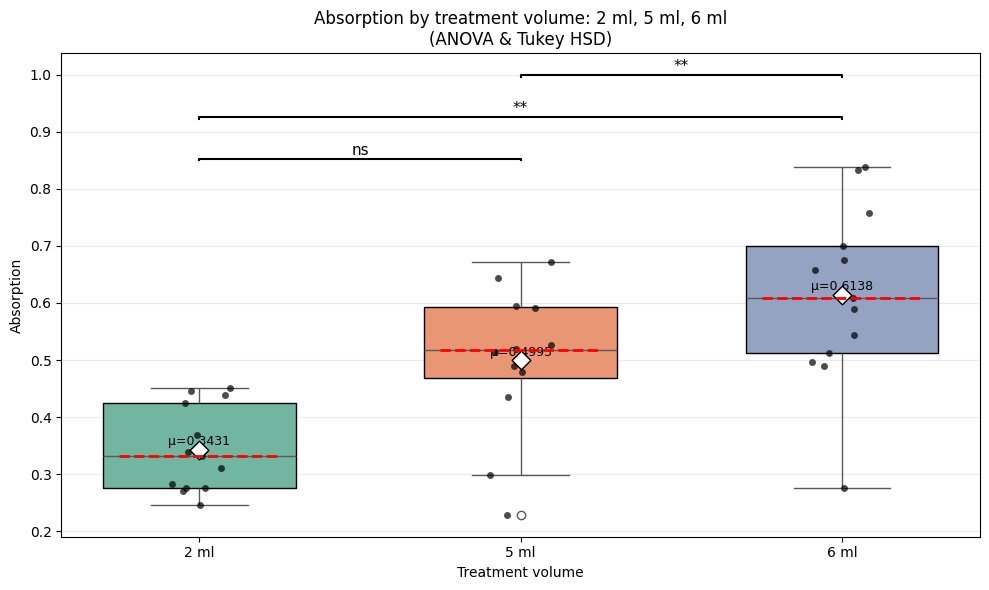

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd # ¡Importante!

# [Toda tu lógica anterior de carga, filtrado y resumen queda igual]
selected = merged_all[merged_all['treatment_value'].isin([2, 5, 6])].copy()
selected['treatment_label'] = selected['treatment_value'].astype(str) + ' ml'
selected = selected.sort_values('treatment_value')

summary = selected.groupby('treatment_label')['absorption'].agg(['median', 'mean', 'count']).reset_index()

groups = [selected[selected['treatment_label'] == label]['absorption'] for label in ['2 ml', '5 ml', '6 ml']]

# 1. Normalidad y Homocedasticidad (Tu bloque de validación)
print("--- Normalidad ---")
for i, g in enumerate(groups):
    stat, p = stats.shapiro(g)
    print(f"Grupo {i+1}: p={p:.4f} -> {'Normal' if p > 0.05 else 'No Normal'}")

stat, p = stats.levene(*groups)
print(f"\n--- Homocedasticidad (Levene) ---")
print(f"p={p:.4f} -> {'Homocedastico' if p > 0.05 else 'Heterocedastico'}\n")

# ==========================================
# NUEVA LÓGICA ESTADÍSTICA (ANOVA + TUKEY)
# ==========================================

# 1. ANOVA Global
f_stat, p_anova = stats.f_oneway(*groups)
print("--- ANOVA de una vía ---")
print(f"F = {f_stat:.4f}, p = {p_anova:.4f}\n")

# Si el p_anova es > 0.05, teóricamente no deberías buscar diferencias por pares.
# Pero corremos Tukey de todos modos para que el script grafique correctamente.

# 2. Tukey HSD Post-Hoc
tukey = pairwise_tukeyhsd(endog=selected['absorption'], 
                          groups=selected['treatment_label'], 
                          alpha=0.05)

print("--- Tukey HSD ---")
print(tukey)

# Extraemos los p-valores ajustados para usarlos en el gráfico
p_values = {}
for i in range(len(tukey.groupsunique)):
    for j in range(i + 1, len(tukey.groupsunique)):
        g1 = tukey.groupsunique[i]
        g2 = tukey.groupsunique[j]
        # El índice correspondiente en la matriz de p-valores
        idx = tukey.groupsunique.tolist().index(g1)
        idx2 = tukey.groupsunique.tolist().index(g2)
        # Hay que encontrar la fila correcta en tukey.pvalues
        # pairwise_tukeyhsd genera las combinaciones en un orden específico.
        # Una forma más segura de mapearlo es iterando sobre los resultados:
        pass

# Forma segura de armar el diccionario p_values desde el objeto tukey:
p_values = {}
for i, group1 in enumerate(tukey.groupsunique[:-1]):
    for j, group2 in enumerate(tukey.groupsunique[i+1:]):
        # pair_idx calcula la posición plana en los arrays de resultados de Tukey
        n_groups = len(tukey.groupsunique)
        pair_idx = int(i * (n_groups - (i + 1) / 2) + j - i - 1)
        
        p_val = tukey.pvalues[pair_idx]
        p_values[(group1, group2)] = p_val
        p_values[(group2, group1)] = p_val # Por si el orden se invierte al graficar

# ==========================================
# GRÁFICOS (Casi igual, pero leyendo de p_values de Tukey)
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=selected,
    x='treatment_label',
    y='absorption',
    ax=ax,
    palette='Set2',
    width=0.6,
    showcaps=True,
    boxprops={'edgecolor': 'black'},
)
sns.stripplot(
    data=selected,
    x='treatment_label',
    y='absorption',
    ax=ax,
    color='black',
    size=5,
    alpha=0.7,
    jitter=True,
)

for i, row in summary.iterrows():
    ax.scatter(i, row['mean'], color='white', edgecolor='black', marker='D', s=90, zorder=10)
    ax.hlines(row['median'], i - 0.25, i + 0.25, color='red', linestyle='--', linewidth=2, zorder=11)
    ax.text(i, row['mean'] + 0.003, f'μ={row['mean']:.4f}', ha='center', va='bottom', fontsize=9)

def sig_marker(p):
    if p <= 0.001: return '***'
    if p <= 0.01: return '**'
    if p <= 0.05: return '*'
    return 'ns'

pairs = [('2 ml', '5 ml'), ('2 ml', '6 ml'), ('5 ml', '6 ml')]

max_y = selected['absorption'].max()
min_y = selected['absorption'].min()
y_spacing = (max_y - min_y) * 0.12
base_y = max_y + y_spacing * 0.15

for idx, (a, b) in enumerate(pairs):
    x1 = summary.index[summary['treatment_label'] == a].tolist()[0]
    x2 = summary.index[summary['treatment_label'] == b].tolist()[0]
    y = base_y + idx * y_spacing
    ax.plot([x1, x1, x2, x2], [y, y + y_spacing * 0.04, y + y_spacing * 0.04, y], color='black')
    
    # Buscamos el p-valor de Tukey
    p_val = p_values.get((a, b))
    ax.text((x1 + x2) / 2, y + y_spacing * 0.06, sig_marker(p_val), ha='center', va='bottom', fontsize=11)

ax.set_title('Absorption by treatment volume: 2 ml, 5 ml, 6 ml\n(ANOVA & Tukey HSD)')
ax.set_xlabel('Treatment volume')
ax.set_ylabel('Absorption')
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()